# ReceiptReader 17% — v10 FINAL RESEARCH CANDIDATE

**What changes:** real-image OCR variants (original, CLAHE, adaptive threshold), validation-only tuning without contamination, OCR address-coverage diagnostics, regex/neighbor address selection, fixed holdout evaluation, CORD-assisted total baseline and model exports. **No guarantee of improvement.**

**Important:** The SROIE official test has been used in versions 1–9, so the evaluation below is a *repeated benchmark*, not untouched generalization. Automatic finance extraction requires human review.

In [1]:
import os, sys, re, io, json, random, hashlib, zipfile, shutil, warnings
from pathlib import Path
from collections import Counter
from datetime import datetime
from difflib import SequenceMatcher
import numpy as np, pandas as pd, pyarrow.parquet as pq, joblib, matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
warnings.filterwarnings('ignore', category=FutureWarning)
SEED=42; random.seed(SEED); np.random.seed(SEED)
ROOT=Path('/kaggle/working/receiptreader_17pct_v10'); REPORT=ROOT/'reports'; FIG=ROOT/'plots'; MODELS=ROOT/'models'; EXPORT=ROOT/'exports'
for p in (REPORT,FIG,MODELS,EXPORT):p.mkdir(parents=True,exist_ok=True)
def js(path,obj):Path(path).write_text(json.dumps(obj,indent=2,ensure_ascii=False,default=str),encoding='utf8')
def plot(name):plt.tight_layout();plt.savefig(FIG/name,dpi=150,bbox_inches='tight');plt.show();plt.close()
print('Environment:',sys.version);print('Input root:',list(Path('/kaggle/input').iterdir()) if Path('/kaggle/input').exists() else 'not Kaggle')

Environment: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Input root: [PosixPath('/kaggle/input/datasets')]


In [2]:
BASE=Path('/kaggle/input')
def discover(hint):
    preferred=BASE/'datasets'/'wafabila'/hint
    if preferred.exists():return preferred
    matches=[p for p in BASE.rglob('*') if p.is_dir() and p.name.lower()==hint.lower()]
    if not matches:raise FileNotFoundError(f'Missing dataset {hint}. Attach it in Kaggle Inputs.')
    return sorted(matches,key=lambda p:len(str(p)))[0]
SROOT=discover('receiptreader-sroie'); CROOT=discover('cord-v2')
def splitfiles(root,prefix):
    fs=sorted(p for p in root.rglob('*.parquet') if p.name.startswith(prefix+'-'))
    if not fs:raise FileNotFoundError(f'No {prefix} Parquet in {root}')
    return fs
s_train=splitfiles(SROOT,'train');s_test=splitfiles(SROOT,'test')
c_train=splitfiles(CROOT,'train');c_val=splitfiles(CROOT,'validation');c_test=splitfiles(CROOT,'test')
print('SROIE files',len(s_train),len(s_test),'CORD files',len(c_train),len(c_val),len(c_test))
for title,fs in [('SROIE TRAIN',s_train),('SROIE TEST',s_test),('CORD TRAIN',c_train),('CORD VAL',c_val),('CORD TEST',c_test)]:
    print(title,'rows',sum(pq.ParquetFile(f).metadata.num_rows for f in fs),'schema',pq.ParquetFile(fs[0]).schema_arrow.names)
assert {'image','entities','words','bboxes','image_size'}.issubset(set(pq.ParquetFile(s_train[0]).schema_arrow.names))
assert {'image','ground_truth'}.issubset(set(pq.ParquetFile(c_train[0]).schema_arrow.names))
# CORD official validation/test are NEVER training examples.
sdf=pd.concat([pd.read_parquet(f) for f in s_train],ignore_index=True)
test=pd.concat([pd.read_parquet(f) for f in s_test],ignore_index=True)
cord=pd.concat([pd.read_parquet(f) for f in c_train],ignore_index=True)
assert len(sdf)>=100 and len(test)>=50 and len(cord)>=100
print('Read:',len(sdf),'SROIE train,',len(test),'SROIE test,',len(cord),'CORD train')

SROIE files 1 1 CORD files 4 1 1
SROIE TRAIN rows 626 schema ['image', 'key', 'image_size', 'entities', 'words', 'bboxes']
SROIE TEST rows 361 schema ['image', 'key', 'image_size', 'entities', 'words', 'bboxes']
CORD TRAIN rows 800 schema ['image', 'ground_truth']
CORD VAL rows 100 schema ['image', 'ground_truth']
CORD TEST rows 100 schema ['image', 'ground_truth']
Read: 626 SROIE train, 361 SROIE test, 800 CORD train


In [3]:
FIELDS=('company','date','address','total')
def dct(x):return x if isinstance(x,dict) else dict(x) if hasattr(x,'items') else {}
def seq(x):return x.tolist() if isinstance(x,np.ndarray) else list(x) if isinstance(x,(tuple,list)) else []
def norm(s):return re.sub('[^A-Z0-9]','',str(s or '').upper())
def toks(s):return re.findall('[A-Z0-9]+',str(s or '').upper())
def token_f1(a,b):
    x,y=Counter(toks(a)),Counter(toks(b));k=sum((x&y).values());den=sum(x.values())+sum(y.values());return 2*k/den if den else 1.
def money(s):
    # SROIE uses decimal dot; CORD uses Indonesian comma thousands (e.g. 1,591,600)
    s=str(s or '').strip().upper().replace('RP','').replace('IDR','').replace('RM','').replace(' ','')
    s=re.sub('[^0-9,.]','',s)
    if not s:return None
    if ',' in s and '.' in s:
        s=s.replace(',','') if s.rfind('.')>s.rfind(',') else s.replace('.','').replace(',','.')
    elif ',' in s:
        parts=s.split(',');s=''.join(parts) if len(parts)>2 or (len(parts)==2 and len(parts[-1])==3) else s.replace(',','.')
    try:return round(float(s),2)
    except ValueError:return None
def dateparse(s):
    pats=(r'\b\d{1,2}[/.-]\d{1,2}[/.-]\d{2,4}\b',r'\b\d{4}[/.-]\d{1,2}[/.-]\d{1,2}\b')
    fmts=('%d/%m/%Y','%d/%m/%y','%d-%m-%Y','%d-%m-%y','%d.%m.%Y','%d.%m.%y','%Y-%m-%d','%Y/%m/%d')
    for pat in pats:
        for m in re.finditer(pat,str(s)):
            for fmt in fmts:
                try:return datetime.strptime(m.group(),fmt).date().isoformat()
                except ValueError:pass
    return ''
def field_equal(f,p,t):
    if not str(t).strip():return not str(p).strip()
    if f=='total':return money(p) is not None and money(t) is not None and abs(money(p)-money(t))<.005
    if f=='date':return bool(dateparse(p) and dateparse(p)==dateparse(t))
    return norm(p)==norm(t)
def sent(row):return {f:str(dct(row['entities']).get(f) or '').strip() for f in FIELDS}
def simage(row):
    obj=dct(row['image']);b=obj.get('bytes')
    if b is not None:return Image.open(io.BytesIO(b)).convert('RGB')
    return Image.open(obj['path']).convert('RGB')
def sha(row):
    obj=dct(row['image']);b=obj.get('bytes')
    return hashlib.sha256(b if b is not None else simage(row).tobytes()).hexdigest()
def sregs(row):
    sz=dct(row['image_size']);w=max(1,int(sz.get('width',1)));h=max(1,int(sz.get('height',1)))
    out=[]
    for text,bb in zip(seq(row['words']),seq(row['bboxes'])):
        b=seq(bb)
        if len(b)!=4 or not str(text).strip():continue
        x0,y0,x1,y1=map(float,b)
        out.append(dict(text=str(text).strip(),x=x0/w,y=y0/h,w=max(0,x1-x0)/w,h=max(0,y1-y0)/h))
    return sorted(out,key=lambda r:(round(r['y'],4),r['x']))
def cord_gt(row):
    raw=row['ground_truth'];return json.loads(raw) if isinstance(raw,str) else dct(raw)
first=cord_gt(cord.iloc[0]);print('CORD top-level',list(first));print('CORD gt_parse categories',list(first.get('gt_parse',{})))
print('CORD first total:',first.get('gt_parse',{}).get('total'))
assert 'valid_line' in first and 'gt_parse' in first
js(REPORT/'cord_schema_example.json',{'keys':list(first),'gt_parse_categories':list(first['gt_parse']),'sample_total':first['gt_parse'].get('total')})

CORD top-level ['gt_parse', 'meta', 'valid_line', 'roi', 'repeating_symbol', 'dontcare']
CORD gt_parse categories ['menu', 'sub_total', 'total']
CORD first total: {'total_price': '1,591,600'}


In [4]:
def cregs(row):
    gt=cord_gt(row); size=dct(dct(gt.get('meta',{})).get('image_size',{}));w=max(1,int(size.get('width') or 1));h=max(1,int(size.get('height') or 1));out=[]
    for line in gt.get('valid_line',[]):
        words=line.get('words',[]);pieces=[];xs=[];ys=[]
        for word in words:
            text=str(word.get('text') or '').strip();q=dct(word.get('quad'))
            if not text:continue
            vx=[float(q[k]) for k in ('x1','x2','x3','x4') if k in q];vy=[float(q[k]) for k in ('y1','y2','y3','y4') if k in q]
            if not vx or not vy:continue
            pieces.append((min(vx),text));xs+=vx;ys+=vy
        if not pieces:continue
        pieces.sort(key=lambda z:z[0]);x0=min(xs);x1=max(xs);y0=min(ys);y1=max(ys)
        out.append(dict(text=' '.join(p[1] for p in pieces),x=x0/w,y=y0/h,w=max(0,x1-x0)/w,h=max(0,y1-y0)/h,category=line.get('category','')))
    return sorted(out,key=lambda r:(round(r['y'],4),r['x']))
def ctarget(row):return str(dct(dct(cord_gt(row).get('gt_parse',{})).get('total',{})).get('total_price') or '')
for i in range(3):
    print('CORD',i,'total',ctarget(cord.iloc[i]),'regions',len(cregs(cord.iloc[i])),'types',Counter(r['category'] for r in cregs(cord.iloc[i])).most_common(5))
print('CORD labels are NOT company/date/address. Training must not invent those labels.')

CORD 0 total 1,591,600 regions 71 types [('menu.nm', 22), ('menu.price', 22), ('menu.cnt', 22), ('sub_total.subtotal_price', 1), ('sub_total.service_price', 1)]
CORD 1 total 580,965 regions 24 types [('menu.price', 6), ('menu.cnt', 6), ('menu.nm', 6), ('menu.sub.nm', 2), ('sub_total.subtotal_price', 1)]
CORD 2 total 334,000 regions 21 types [('menu.price', 5), ('menu.nm', 5), ('menu.cnt', 5), ('sub_total.subtotal_price', 1), ('total.total_price', 1)]
CORD labels are NOT company/date/address. Training must not invent those labels.


{'sroie_training': 626, 'sroie_internal_training': 501, 'sroie_validation': 125, 'sroie_test': 361, 'sroie_hash_clean_repeated_test': 353, 'overlap_excluded': 8, 'cord_official_training': 800, 'cord_validation_not_used_to_train': True, 'cord_test_not_used_to_train': True}


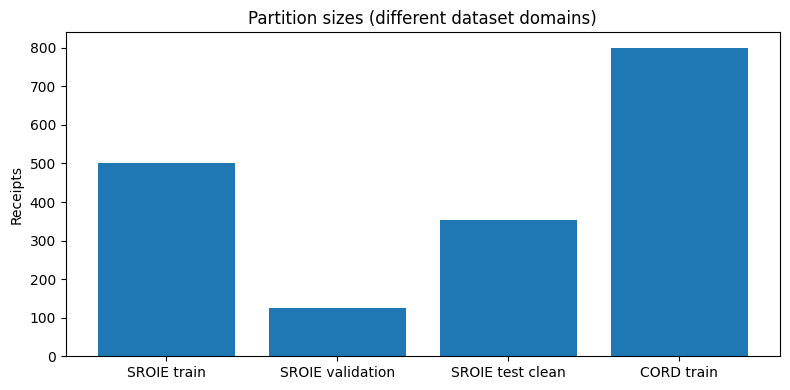

In [5]:
hs=[sha(row) for _,row in sdf.iterrows()];ht=[sha(row) for _,row in test.iterrows()]
itr,iva=next(GroupShuffleSplit(n_splits=1,test_size=.20,random_state=SEED).split(sdf,groups=hs))
assert set(hs[i] for i in itr).isdisjoint(set(hs[i] for i in iva))
clean=np.array([i for i,h in enumerate(ht) if h not in set(hs)],dtype=int)
assert len(clean)>0
meta={'sroie_training':len(sdf),'sroie_internal_training':len(itr),'sroie_validation':len(iva),'sroie_test':len(test),'sroie_hash_clean_repeated_test':len(clean),'overlap_excluded':len(test)-len(clean),'cord_official_training':len(cord),'cord_validation_not_used_to_train':True,'cord_test_not_used_to_train':True}
print(meta);js(REPORT/'split_audit.json',meta)
fig,ax=plt.subplots(figsize=(8,4));ax.bar(['SROIE train','SROIE validation','SROIE test clean','CORD train'],[len(itr),len(iva),len(clean),len(cord)]);ax.set_ylabel('Receipts');ax.set_title('Partition sizes (different dataset domains)');plot('01_partitions.png')

In [6]:
AMOUNT_RX=re.compile(r'(?<![A-Za-z0-9])(?:RP\.?\s*|IDR\s*|RM\s*|MYR\s*|\$\s*)?(\d{1,3}(?:[.,]\d{3})+(?:[.,]\d{2})?|\d{1,9}[.,]\d{2}|\d{1,9})(?![A-Za-z0-9])',re.I)
HINT=('GRAND TOTAL','TOTAL','AMOUNT DUE','NETT','JUMLAH','BAYAR','TOTAL PRICE')
NEG=('SUBTOTAL','SUB TOTAL','CHANGE','CASH','TAX','GST','SST','QTY','PRICE','KEMBALI','PAJAK','SERVICE')
def amount_candidates(rs):
    arr=[]
    for i,r in enumerate(rs):
        text=r['text'];context=' '.join(z['text'] for z in rs[max(0,i-2):i+3]).upper()
        for match in AMOUNT_RX.finditer(text):
            raw=match.group(1);value=money(raw)
            if value is None:continue
            arr.append(dict(context=context,x=r['x'],y=r['y'],value=value,raw=raw,own_hint=int(any(t in text.upper() for t in HINT)),near_hint=int(any(t in context for t in HINT)),own_negative=int(any(t in text.upper() for t in NEG)),near_negative=int(any(t in context for t in NEG)),n_chars=len(text),n_tokens=len(text.split()),is_decimal=int('.' in raw),is_thousand=int(',' in raw)))
    return arr
MF=['context','x','y','value','own_hint','near_hint','own_negative','near_negative','n_chars','n_tokens','is_decimal','is_thousand'];MN=[x for x in MF if x!='context']
def records_amounts(df,indices,getreg,gettruth,domain):
    rows=[];coverage=[]
    for ix in indices:
        row=df.iloc[int(ix)];cs=amount_candidates(getreg(row));gt=money(gettruth(row));hits=0
        for c in cs:
            label=int(gt is not None and abs(c['value']-gt)<.005);hits+=label
            rows.append({**c,'label':label,'domain':domain,'receipt_id':domain+'_'+str(int(ix))})
        coverage.append({'row':int(ix),'domain':domain,'has_target':int(gt is not None),'covered':int(hits>0),'n_candidates':len(cs)})
    return pd.DataFrame(rows),pd.DataFrame(coverage)
st_amount,st_cov=records_amounts(sdf,itr,sregs,lambda r:sent(r)['total'],'sroie')
co_amount,co_cov=records_amounts(cord,range(len(cord)),cregs,ctarget,'cord')
print('SROIE amount coverage',st_cov.covered.mean(),'CORD amount coverage',co_cov.covered.mean())
print('Rows SROIE',len(st_amount),'CORD',len(co_amount),'positive SROIE',st_amount.label.sum(),'positive CORD',co_amount.label.sum())
assert st_amount.label.nunique()==2,'SROIE amount labels are single class'
assert len(co_amount)>0,'CORD has no amount candidates: review CORD line parsing'
st_cov.to_csv(REPORT/'sroie_train_amount_coverage.csv',index=False);co_cov.to_csv(REPORT/'cord_train_amount_coverage.csv',index=False)
js(REPORT/'amount_feasibility.json',{'sroie_train_candidate_recall':float(st_cov.loc[st_cov.has_target.eq(1),'covered'].mean()),'cord_train_candidate_recall':float(co_cov.loc[co_cov.has_target.eq(1),'covered'].mean()),'cord_missing_target':int(co_cov.has_target.eq(0).sum())})

SROIE amount coverage 0.9940119760479041 CORD amount coverage 0.96375
Rows SROIE 17982 CORD 8833 positive SROIE 1346 positive CORD 1576


In [7]:
def balance_rows(df,max_neg=18):
    out=[]
    for _,g in df.groupby('receipt_id',sort=False):
        pos=g[g.label.eq(1)];neg=g[g.label.eq(0)].sort_values(['near_hint','y'],ascending=[False,False]).head(max_neg)
        out.append(pd.concat([pos,neg]))
    return pd.concat(out,ignore_index=True) if out else pd.DataFrame(columns=df.columns)
sa=balance_rows(st_amount);ca=balance_rows(co_amount)
def ranker(C=2.):
    return Pipeline([('prep',ColumnTransformer([('chars',TfidfVectorizer(analyzer='char',ngram_range=(2,4),min_df=2,max_features=12000),'context'),('nums',StandardScaler(),MN)])),('clf',LogisticRegression(C=C,class_weight='balanced',max_iter=1000,random_state=SEED))])
model_A=ranker();model_A.fit(sa[MF],sa.label)
combo=pd.concat([sa,ca],ignore_index=True)
# Domain-level weighting prevents 800 Indonesian receipts from swamping 501 Malaysian receipts.
weights=np.where(combo.domain.eq('cord'),0.35,1.0)
model_B=ranker();model_B.fit(combo[MF],combo.label,clf__sample_weight=weights)
def predict_total(model,rs):
    cs=amount_candidates(rs)
    if not cs:return ''
    prob=model.predict_proba(pd.DataFrame(cs)[MF])[:,1]
    k=int(np.argmax(prob))
    return f"{cs[k]['value']:.2f}" if prob[k]>=.10 else ''
def total_eval(df,indices,getreg,gettruth,model):
    out=[]
    for ix in indices:
        row=df.iloc[int(ix)];pred=predict_total(model,getreg(row));ref=gettruth(row)
        out.append({'row':int(ix),'pred':pred,'true':ref,'exact':int(field_equal('total',pred,ref))})
    return pd.DataFrame(out)
va_A=total_eval(sdf,iva,sregs,lambda r:sent(r)['total'],model_A)
va_B=total_eval(sdf,iva,sregs,lambda r:sent(r)['total'],model_B)
valscore={'sroie_only':float(va_A.exact.mean()),'cord_augmented':float(va_B.exact.mean())}
winner='cord_augmented' if valscore['cord_augmented']>valscore['sroie_only'] else 'sroie_only'
print('SROIE VAL total exact:',valscore,'WINNER (ties prefer simpler SROIE-only):',winner)
js(REPORT/'total_comparison_validation.json',{'scores':valscore,'selected':winner,'selection_policy':'SROIE validation total exact; ties choose SROIE only'})
va_A.to_csv(REPORT/'validation_sroie_only_total.csv',index=False);va_B.to_csv(REPORT/'validation_cord_augmented_total.csv',index=False)

SROIE VAL total exact: {'sroie_only': 0.808, 'cord_augmented': 0.824} WINNER (ties prefer simpler SROIE-only): cord_augmented


In [8]:
ADD_HINT=('JALAN','JLN','NO.','LOT','TAMAN','BANDAR','SELANGOR','JOHOR','KUALA','PERSIARAN','ROAD','STREET','BATU','POSKOD')
FREG=['text','x','y','w','h','position','n_chars','n_digits','address_hint','date_hint','total_hint'];NREG=[q for q in FREG if q!='text']
def rfeatures(rs):
    return [{**r,'position':j/max(1,len(rs)),'n_chars':len(r['text']),'n_digits':sum(c.isdigit() for c in r['text']),'address_hint':int(any(h in r['text'].upper() for h in ADD_HINT)),'date_hint':int(bool(re.search(r'\b(?:DATE|TARIKH)\b',r['text'],re.I))),'total_hint':int(bool(re.search(r'\b(?:TOTAL|NETT|JUMLAH)\b',r['text'],re.I)))} for j,r in enumerate(rs)]
def weak_lbl(text,targets):
    s=norm(text)
    if not s:return 'other'
    c=norm(targets['company']);a=norm(targets['address'])
    if c and len(s)>6 and (s==c or SequenceMatcher(None,s,c).ratio()>.86):return 'company'
    if dateparse(text) and dateparse(text)==dateparse(targets['date']):return 'date'
    if a and len(s)>=5 and s in a:return 'address'
    return 'other'
def region_training(df,ids):
    rows=[]
    for i in ids:
        r=df.iloc[int(i)];gt=sent(r)
        for z in rfeatures(sregs(r)):rows.append({**z,'label':weak_lbl(z['text'],gt)})
    return pd.DataFrame(rows)
def make_region():return Pipeline([('prep',ColumnTransformer([('char',TfidfVectorizer(analyzer='char',ngram_range=(2,4),min_df=2,max_features=16000),'text'),('num',StandardScaler(),NREG)])),('clf',LogisticRegression(C=2,class_weight='balanced',max_iter=1000,random_state=SEED))])
rf=region_training(sdf,itr);print('Weak region classes:',rf.label.value_counts().to_dict())
assert {'company','address','date','other'}.issubset(set(rf.label))
region_model=make_region().fit(rf[FREG],rf.label)
def other_fields(rs,model,address_threshold=.52):
    result={'company':'','date':'','address':''}
    if not rs:return result
    x=pd.DataFrame(rfeatures(rs));p=model.predict_proba(x[FREG]);classes=list(model.named_steps['clf'].classes_)
    pp=p[:,classes.index('company')];ii=int(np.argmax(pp))
    if pp[ii]>=.20:result['company']=rs[ii]['text']
    dates=[]
    for r in rs:
        dt=dateparse(r['text'])
        if dt:dates.append((1+2*int(bool(re.search(r'\b(?:DATE|TARIKH)\b',r['text'],re.I)))-r['y'],dt))
    if dates:result['date']=max(dates)[1]
    pa=p[:,classes.index('address')]
    hits=[i for i,r in enumerate(rs) if pa[i]>=address_threshold and r['y']<.72 and not re.search(r'\b(?:DATE|TOTAL|CASHIER|INVOICE|QTY|SUBTOTAL)\b',r['text'],re.I)]
    groups=[]
    if hits:
        curr=[hits[0]]
        for i in hits[1:]:
            if i==curr[-1]+1 and rs[i]['y']-rs[curr[-1]]['y']<.07:curr.append(i)
            else:groups.append(curr);curr=[i]
        groups.append(curr)
        best=max(groups,key=lambda a:sum(pa[j] for j in a)+.08*len(a))
        result['address']=' '.join(rs[i]['text'] for i in best)
    return result
def addr_eval(df,idxs,model,th):
    out=[]
    for i in idxs:
        row=df.iloc[int(i)];g=sent(row);prediction=other_fields(sregs(row),model,th)
        out.append(dict(row=int(i),exact=int(field_equal('address',prediction['address'],g['address'])),token_f1=token_f1(prediction['address'],g['address'])))
    return pd.DataFrame(out)
address_trials=[]
for th in (.35,.45,.52,.60):
    ev=addr_eval(sdf,iva,region_model,th)
    address_trials.append({'threshold':th,'exact':float(ev.exact.mean()),'token_f1':float(ev.token_f1.mean())})
address_grid=pd.DataFrame(address_trials).sort_values(['exact','token_f1'],ascending=False)
address_grid.to_csv(REPORT/'address_validation_grid.csv',index=False);print(address_grid)
ADDRESS_THRESHOLD=float(address_grid.iloc[0]['threshold'])
js(REPORT/'frozen_model_selection.json',{'total':winner,'validation_total_scores':valscore,'address_threshold':ADDRESS_THRESHOLD,'validation_address_exact':float(address_grid.iloc[0]['exact']),'caveat':'Selection uses only original SROIE internal validation'})

Weak region classes: {'other': 24849, 'address': 1098, 'date': 558, 'company': 404}
   threshold  exact  token_f1
0       0.35  0.064  0.607400
1       0.45  0.064  0.584448
2       0.52  0.064  0.574848
3       0.60  0.064  0.569859


## A · Train-only candidate and region models (validation never included)

These models are for choosing pixel-OCR processing and address decoding. **Refitting on full SROIE train is postponed until all settings are frozen.**

In [9]:
region_candidate=region_model
candidate_total=model_B if winner=='cord_augmented' else model_A
print('Candidate training SROIE receipts:',len(itr),'validation receipts:',len(iva))
print('Address weak-label model trained on itr only:',len(itr))

Candidate training SROIE receipts: 501 validation receipts: 125
Address weak-label model trained on itr only: 501


## B · OCR engine and pixel representations

Tesseract PSM 6 and PSM 11 plus CLAHE are compared on a fixed internal-validation subset; no new ground-truth text is created by these transforms.

In [10]:
import shutil
try:
 import pytesseract
except ImportError as exc:
 raise RuntimeError('Install pytesseract in Kaggle notebook') from exc
if shutil.which('tesseract') is None:raise RuntimeError('Tesseract executable not found in Kaggle runtime')
try:import cv2
except ImportError as exc:raise RuntimeError('OpenCV (cv2) required for CLAHE OCR variant') from exc
from collections import defaultdict

def prepare_image(img,variant):
 arr=np.array(img.convert('RGB'))
 if variant=='native':return img
 gray=cv2.cvtColor(arr,cv2.COLOR_RGB2GRAY)
 if variant=='clahe':
  gray=cv2.createCLAHE(clipLimit=2.0,tileGridSize=(8,8)).apply(gray)
 elif variant=='adaptive':
  gray=cv2.GaussianBlur(gray,(3,3),0)
  gray=cv2.adaptiveThreshold(gray,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,cv2.THRESH_BINARY,31,11)
 else:raise ValueError(variant)
 return Image.fromarray(gray)

def pixel_lines(img,psm=6):
 d=pytesseract.image_to_data(img,config=f'--psm {psm}',output_type=pytesseract.Output.DICT)
 groups=defaultdict(list);w,h=img.size
 for j,t in enumerate(d['text']):
  t=str(t).strip()
  if not t:continue
  key=(d['block_num'][j],d['par_num'][j],d['line_num'][j])
  groups[key].append((t,int(d['left'][j]),int(d['top'][j]),int(d['width'][j]),int(d['height'][j])))
 out=[]
 for vals in groups.values():
  vals.sort(key=lambda a:a[1]);x=min(v[1] for v in vals);y=min(v[2] for v in vals)
  x2=max(v[1]+v[3] for v in vals);y2=max(v[2]+v[4] for v in vals)
  out.append(dict(text=' '.join(v[0] for v in vals),x=x/w,y=y/h,w=(x2-x)/w,h=(y2-y)/h))
 return sorted(out,key=lambda r:(r['y'],r['x']))

def char_coverage(ocr_text,truth):
 # Diagnostic of OCR character coverage; not a theoretical exact-match ceiling.
 a=Counter(norm(ocr_text));b=Counter(norm(truth));return sum((a&b).values())/max(1,sum(b.values()))


## C · Address decoders including safer conservative neighbor reconstruction

In [11]:
STREET_RX=re.compile(r'\b(?:JALAN|JLN|TAMAN|LOT|LORONG|JALUR|PERSIARAN|ROAD|STREET|NO\.?|BANDAR)\b',re.I)
CITY_RX=re.compile(r'\b(?:JOHOR|SELANGOR|KUALA|PENANG|PERAK|MELAKA|KLANG|SHAH|BAHRU|SEREMBAN|SABAH|SARAWAK|MALAYSIA)\b',re.I)
STOP_RX=re.compile(r'\b(?:SUBTOTAL|TOTAL|TAX|CHANGE|CASH|QTY|UNIT|PRICE|INVOICE|RECEIPT|GST|SST|AMOUNT|TEL|PHONE|FAX|CASHIER|THANK|DISCOUNT|DATE|TIME)\b',re.I)

def addr_neighbor(rs,model,threshold=.35):
 if not rs:return ''
 features=pd.DataFrame(rfeatures(rs))[FREG]
 cls=list(model.named_steps['clf'].classes_)
 probs=model.predict_proba(features)[:,cls.index('address')]
 options=[]
 for i in range(len(rs)):
  if rs[i]['y']>.68:continue
  for nlines in range(1,6):
   chunk=rs[i:i+nlines]
   if len(chunk)!=nlines or chunk[-1]['y']>.73:break
   if any(chunk[j+1]['y']-(chunk[j]['y']+chunk[j]['h'])>.04 for j in range(len(chunk)-1)):break
   lines=[x['text'] for x in chunk]
   if any(STOP_RX.search(t) for t in lines):continue
   text=' '.join(lines)
   if len(toks(text))<2 or len(text)>190:continue
   p=float(np.mean(probs[i:i+nlines]));street=int(bool(STREET_RX.search(text)));city=int(bool(CITY_RX.search(text)))
   postal=int(bool(re.search(r'\b\d{5}\b',text)))
   if p<threshold and not (street or city):continue
   score=1.8*p+.95*street+.65*city+.5*postal+.2*min(nlines,4)-.35*max(0,nlines-4)
   options.append((score,text))
 return max(options,key=lambda x:x[0])[1] if options else ''

def infer_candidate(rs,region,total_model,mode,th):
 pred=other_fields(rs,region,ADDRESS_THRESHOLD)
 if mode=='neighbor':pred['address']=addr_neighbor(rs,region,th)
 pred['total']=predict_total(total_model,rs)
 return pred


## D · Validation image audit and frozen model selection

Selection criterion: maximize address token F1 and exact-match tie-break; if no **≥2 percentage-point** token-F1 gain over native PSM6 base, preserve base. Crucially, `region_candidate` and `candidate_total` have only seen the `itr` split and CORD official training. Even preprocessing mode is selected only on validation.

In [12]:
PIXEL_VAL_MAX=80
VAL_IDS=sorted(map(int,iva))[:PIXEL_VAL_MAX]
OCR_OPTIONS=[('native',6),('native',11),('clahe',6),('adaptive',6)]
DECODER_OPTIONS=[('base',ADDRESS_THRESHOLD),('neighbor',.20),('neighbor',.35)]
val_cached=[]
for k,i in enumerate(VAL_IDS):
 if k%10==0:print('[VAL OCR]',k,'/',len(VAL_IDS),flush=True)
 row=sdf.iloc[i];gt=sent(row);img=simage(row);versions={};errors={}
 for variant,psm in OCR_OPTIONS:
  try:versions[(variant,psm)]=pixel_lines(prepare_image(img,variant),psm)
  except Exception as exc:versions[(variant,psm)]=[];errors[f'{variant}-{psm}']=repr(exc)
 val_cached.append((i,gt,versions,errors))
rows=[];cv=[]
for variant,psm in OCR_OPTIONS:
 for mode,threshold in DECODER_OPTIONS:
  per=[]
  for i,gt,versions,errors in val_cached:
   rs=versions[(variant,psm)]
   pred=infer_candidate(rs,region_candidate,candidate_total,mode,threshold)
   per.append({'row':i,'address_f1':token_f1(pred['address'],gt['address']),
               'address_exact':int(field_equal('address',pred['address'],gt['address'])),
               'all_four':int(all(field_equal(f,pred[f],gt[f]) for f in FIELDS))})
  dd=pd.DataFrame(per)
  rows.append({'variant':variant,'psm':psm,'decoder':mode,'threshold':float(threshold),
               'address_f1':float(dd.address_f1.mean()),'address_exact':float(dd.address_exact.mean()),
               'all_four_exact':float(dd.all_four.mean()),'n':len(per)})
 for i,gt,versions,errors in val_cached:
  rs=versions[(variant,psm)]
  cv.append({'row':i,'variant':variant,'psm':psm,
             'ocr_char_coverage_address':char_coverage(' '.join(z['text'] for z in rs),gt['address']),
             'errors':errors.get(f'{variant}-{psm}','')})
validation=pd.DataFrame(rows).sort_values(['address_f1','address_exact'],ascending=False)
validation.to_csv(REPORT/'v10_pixel_validation_comparison.csv',index=False)
pd.DataFrame(cv).to_csv(REPORT/'v10_ocr_coverage_diagnostic.csv',index=False)
print(validation.to_string(index=False))
base=validation.query("variant=='native' and psm==6 and decoder=='base'").iloc[0]
champ=validation.iloc[0]
if champ.address_f1 < base.address_f1+.02:champ=base
CHOICE={'variant':str(champ.variant),'psm':int(champ.psm),'decoder':str(champ.decoder),'threshold':float(champ.threshold),
 'validation_address_f1':float(champ.address_f1),'validation_address_exact':float(champ.address_exact),
 'base_address_f1':float(base.address_f1)}
js(REPORT/'v10_frozen_selection.json',CHOICE)
print('FROZEN CHOICE:',CHOICE)


[VAL OCR] 0 / 80
[VAL OCR] 10 / 80
[VAL OCR] 20 / 80
[VAL OCR] 30 / 80
[VAL OCR] 40 / 80
[VAL OCR] 50 / 80
[VAL OCR] 60 / 80
[VAL OCR] 70 / 80
 variant  psm  decoder  threshold  address_f1  address_exact  all_four_exact  n
   clahe    6 neighbor       0.20    0.828244         0.3625          0.0375 80
   clahe    6 neighbor       0.35    0.828244         0.3625          0.0375 80
  native    6     base       0.35    0.817961         0.3875          0.0250 80
   clahe    6     base       0.35    0.810148         0.3750          0.0375 80
  native    6 neighbor       0.20    0.787966         0.3750          0.0250 80
  native    6 neighbor       0.35    0.787966         0.3750          0.0250 80
  native   11 neighbor       0.20    0.740617         0.3375          0.0750 80
  native   11 neighbor       0.35    0.740617         0.3375          0.0750 80
adaptive    6 neighbor       0.20    0.738313         0.1750          0.0000 80
adaptive    6 neighbor       0.35    0.734313         0.1

## E · Only now refit on full official SROIE training, using frozen choices

In [13]:
full_region_data=region_training(sdf,np.arange(len(sdf)))
final_region=make_region().fit(full_region_data[FREG],full_region_data.label)
full_a,_=records_amounts(sdf,np.arange(len(sdf)),sregs,lambda r:sent(r)['total'],'sroie')
full_sa=balance_rows(full_a)
if winner=='cord_augmented':
 train_total=pd.concat([full_sa,ca],ignore_index=True)
 samplew=np.where(train_total.domain.eq('cord'),.35,1.)
else:
 train_total=full_sa;samplew=np.ones(len(train_total))
final_total=ranker().fit(train_total[MF],train_total.label,clf__sample_weight=samplew)
bundle={'region':final_region,'total':final_total,'address_threshold':ADDRESS_THRESHOLD,'choice':CHOICE,
        'version':'v10','total_strategy':winner}
joblib.dump(bundle,MODELS/'receiptreader_v10_bundle.joblib')
def production_predict(image):
 rs=pixel_lines(prepare_image(image,CHOICE['variant']),CHOICE['psm'])
 return infer_candidate(rs,final_region,final_total,CHOICE['decoder'],CHOICE['threshold'])
print('Saved frozen v10 model bundle')


Saved frozen v10 model bundle


## F · Repeated SROIE image benchmark (not an untouched test)

Compare v10 to v8 pixel native-PSM6 base on precisely the same 80 images. **No tuning from these numbers.** Failed OCR counts as four wrong predictions.

[TEST OCR] 0 / 80
[TEST OCR] 10 / 80
[TEST OCR] 20 / 80
[TEST OCR] 30 / 80
[TEST OCR] 40 / 80
[TEST OCR] 50 / 80
[TEST OCR] 60 / 80
[TEST OCR] 70 / 80
{
  "n": 80,
  "failed": 0,
  "note": "repeated SROIE test, not independent",
  "baseline": {
    "company_exact": 0.525,
    "date_exact": 0.75,
    "address_exact": 0.3625,
    "total_exact": 0.55,
    "address_token_f1": 0.8569938196672346,
    "macro_exact": 0.546875,
    "all_four_exact": 0.05
  },
  "v10": {
    "company_exact": 0.525,
    "date_exact": 0.75,
    "address_exact": 0.3625,
    "total_exact": 0.55,
    "address_token_f1": 0.8569938196672346,
    "macro_exact": 0.546875,
    "all_four_exact": 0.05
  }
}


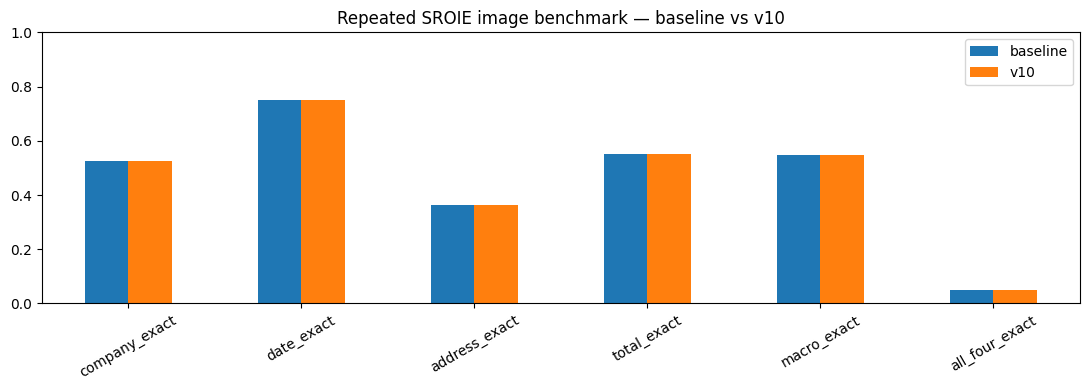

In [14]:
PIXEL_TEST_MAX=80
results=[]
for j,i in enumerate(clean[:PIXEL_TEST_MAX]):
 if j%10==0:print('[TEST OCR]',j,'/',min(PIXEL_TEST_MAX,len(clean)),flush=True)
 row=test.iloc[int(i)];gt=sent(row);result={'row':int(i),'error':''}
 try:
  img=simage(row)
  baseline=infer_candidate(pixel_lines(img,6),final_region,final_total,'base',ADDRESS_THRESHOLD)
  selected=production_predict(img)
  for label,pred in [('baseline',baseline),('v10',selected)]:
   for f in FIELDS:
    result[f'{label}_pred_{f}']=pred[f]
    result[f'{label}_match_{f}']=int(field_equal(f,pred[f],gt[f]))
   result[f'{label}_address_token_f1']=token_f1(pred['address'],gt['address'])
   result[f'{label}_all_four']=int(all(result[f'{label}_match_{f}'] for f in FIELDS))
 except Exception as exc:
  result['error']=repr(exc)
  for label in ('baseline','v10'):
   for f in FIELDS:result[f'{label}_match_{f}']=0
   result[f'{label}_address_token_f1']=0.
   result[f'{label}_all_four']=0
 results.append(result)
predictions=pd.DataFrame(results)
predictions.to_csv(REPORT/'v10_repeated_pixel_predictions.csv',index=False)
metrics={'n':len(predictions),'failed':int(predictions.error.ne('').sum()),'note':'repeated SROIE test, not independent'}
for label in ('baseline','v10'):
 m={f+'_exact':float(predictions[f'{label}_match_{f}'].mean()) for f in FIELDS}
 m['address_token_f1']=float(predictions[f'{label}_address_token_f1'].mean())
 m['macro_exact']=float(np.mean([m[f+'_exact'] for f in FIELDS]))
 m['all_four_exact']=float(predictions[f'{label}_all_four'].mean())
 metrics[label]=m
js(REPORT/'v10_repeated_pixel_metrics.json',metrics)
print(json.dumps(metrics,indent=2))
pd.DataFrame({'baseline':metrics['baseline'],'v10':metrics['v10']}).drop(index='address_token_f1').plot.bar(figsize=(11,4),rot=30)
plt.title('Repeated SROIE image benchmark — baseline vs v10');plt.ylim(0,1);plot('v10_comparison.png')


## G · CORD validation transfer diagnostic, qualitative examples, and export

In [15]:
cord_val_df=pd.concat([pd.read_parquet(f) for f in c_val],ignore_index=True)
cord_ev=total_eval(cord_val_df,range(len(cord_val_df)),cregs,ctarget,final_total)
cord_ev.to_csv(REPORT/'v10_cord_validation_total.csv',index=False)
summary={'version':'v10','datasets':['SROIE','CORD v2'],'selection':CHOICE,'sroie_validation_total':valscore,
         'repeated_pixel_metrics':metrics,'cord_validation_total_exact':float(cord_ev.exact.mean()),
         'limitations':['Official SROIE test previously inspected (v1-v9). Not untouched.',
          'OCR output can miss source characters; no decoder can reliably restore missing evidence.',
          'CORD supplies total supervision only for target fields.',
          'No manual SROIE address annotation corrections included.',
          'Financial outputs require human verification.']}
js(REPORT/'v10_summary.json',summary)
(EXPORT/'sample_inference.json').write_text(json.dumps(production_predict(simage(test.iloc[int(clean[0])])),indent=2),encoding='utf-8')
(ROOT/'README.md').write_text("""# ReceiptReader v10

Real pixel OCR evaluation, training-only model selection, address diagnostic, multi-preprocessing experiment.

Use the v10 notebook for `production_predict(image)`. No trustworthy four-field autonomous extraction guarantee.

## Audit
- reports/v10_pixel_validation_comparison.csv
- reports/v10_ocr_coverage_diagnostic.csv
- reports/v10_frozen_selection.json
- reports/v10_repeated_pixel_metrics.json
- reports/v10_repeated_pixel_predictions.csv
- reports/v10_cord_validation_total.csv

Test SROIE reused v1-v9, therefore not untouched.
""",encoding='utf8')
manifest=[]
for p in sorted(ROOT.rglob('*')):
 if p.is_file() and p.name!='MANIFEST.json':manifest.append({'path':p.relative_to(ROOT).as_posix(),'bytes':p.stat().st_size,'sha256':hashlib.sha256(p.read_bytes()).hexdigest()})
js(ROOT/'MANIFEST.json',manifest)
archive=Path('/kaggle/working/ReceiptReader_17pct_FULL_MASTER_v10_FINAL.zip')
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED,allowZip64=True) as z:
 for p in sorted(ROOT.rglob('*')):
  if p.is_file():z.write(p,p.relative_to(ROOT).as_posix())
with zipfile.ZipFile(archive) as z:assert z.testzip() is None
print('FINAL ZIP:',archive,'MiB:',round(archive.stat().st_size/2**20,2))
print('Compare v10 and baseline metrics; do not claim improvement unless observed.')


FINAL ZIP: /kaggle/working/ReceiptReader_17pct_FULL_MASTER_v10_FINAL.zip MiB: 0.83
Compare v10 and baseline metrics; do not claim improvement unless observed.
